In [1]:
import pacmap 
import numpy        as np
import pandas       as pd
import umap.umap_   as umap

from tqdm                               import tqdm
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
#from clustering.clusteringTimeSeries    import ClusteringTimeSeries
from clustering.plotClustering          import ClusteringResults

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
preData.additionEfficiencyVar()
preData.splitTimeSeries()
preData.getHealthyState()
df      = preData.crusher1

scaler  = MinMaxScaler() 
preData.normalizeData(scaler=scaler);

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:391: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod], ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:391: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod], ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\

In [3]:
linePlot(data   = df, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfEfficiencyVar = preData.scaledCrusher1[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2,  
                                        n_jobs      = -1),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3,   
                                        n_jobs      = -1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40),

                       'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:




In [5]:
Clusters = ClusteringResults(data                = preData.crusher1, 
                             dataNormalized      = dfEfficiencyVar, 
                             clusteringModels    = clusteringModels, 
                             dimReductionModels  = dimReductionModels)

In [6]:
# Train dimensionality reduction models wiht a trajectory
Clusters.train(trainTrajectory='15')

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [7]:
# Clusters are calculated in embedding space for each trajectory
for trajectory in tqdm(Clusters.trajectories):
    Clusters.getResults(trajectory)

100%|██████████| 10/10 [01:02<00:00,  6.28s/it]


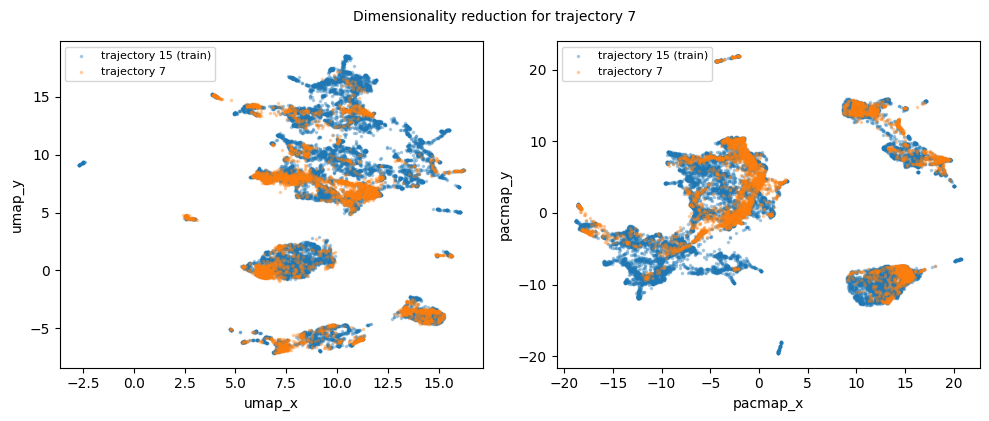

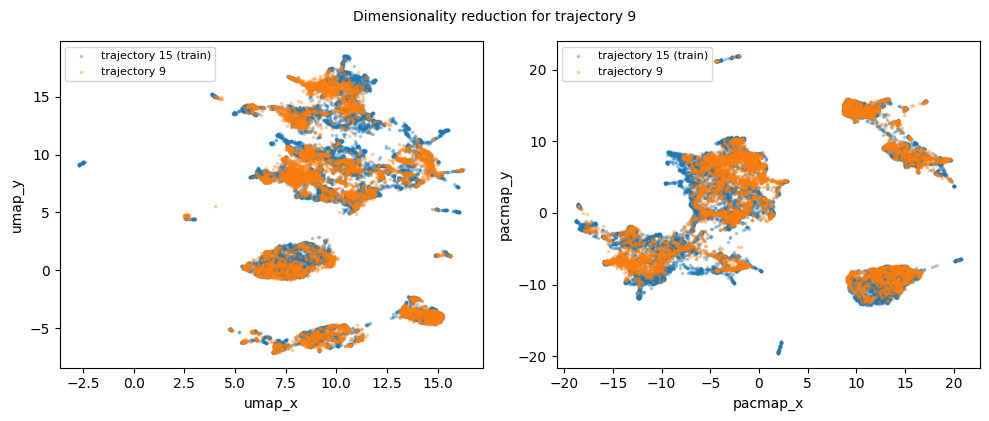

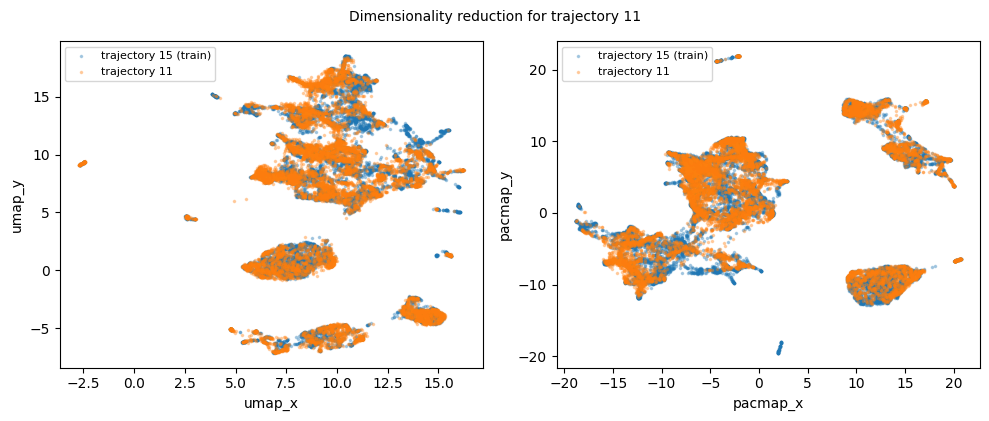

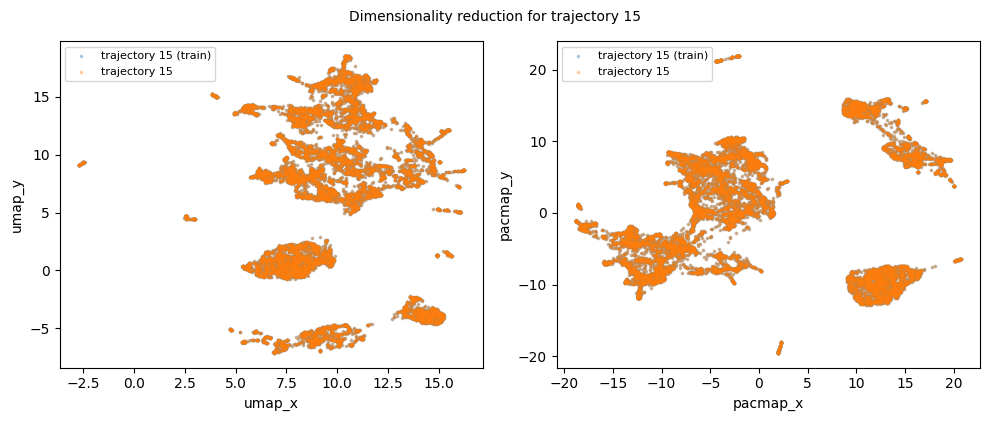

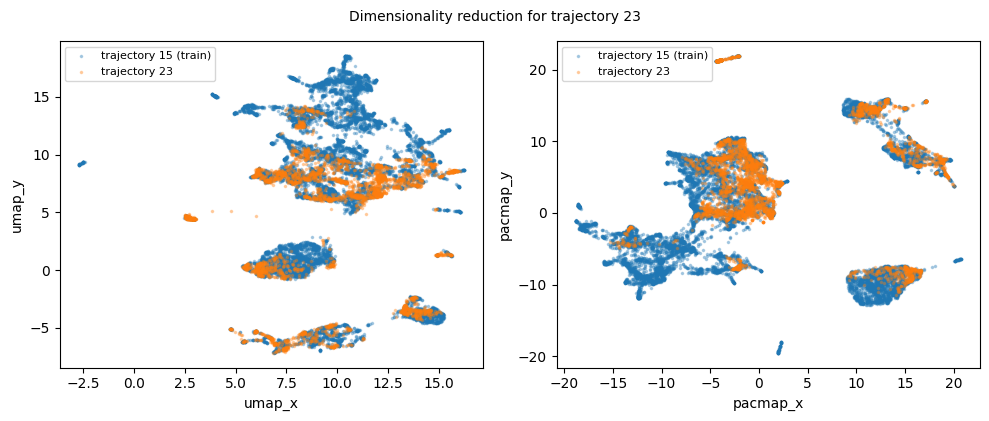

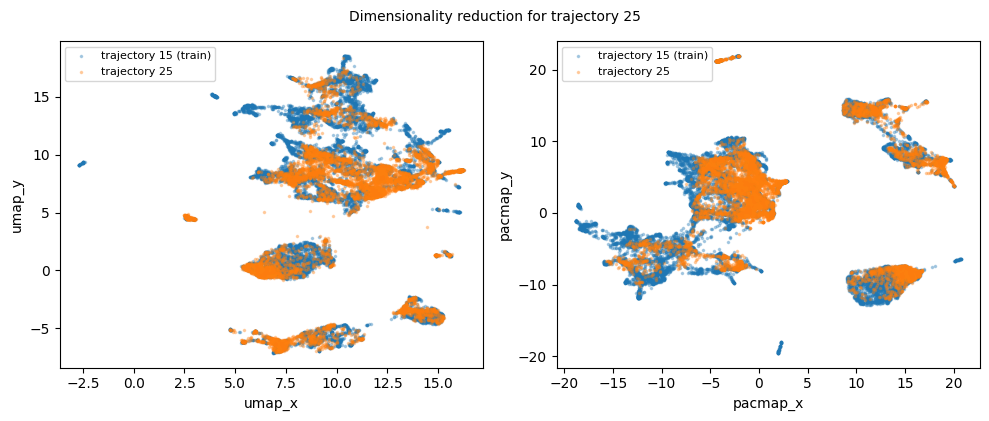

In [ ]:
Clusters.plotEmbedding(nfigures=6)

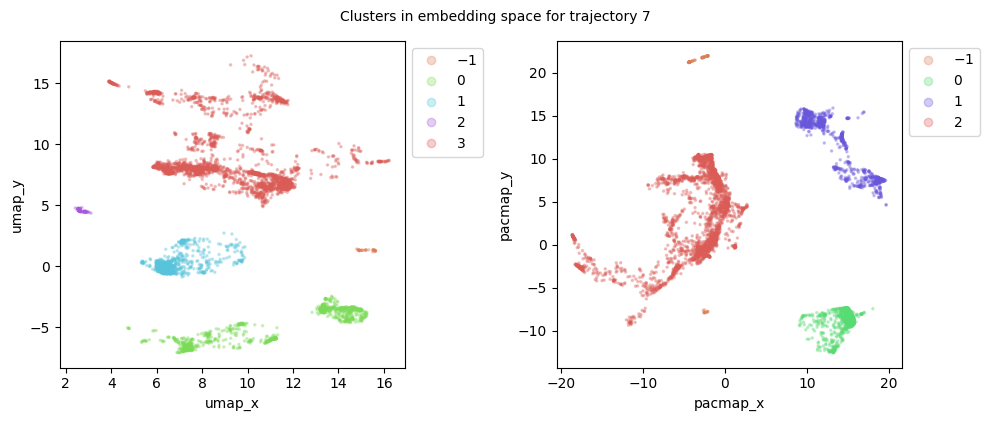

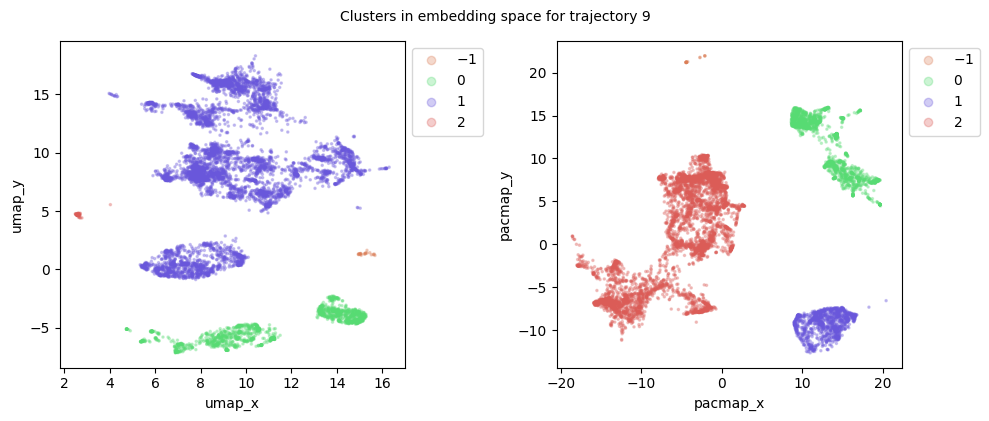

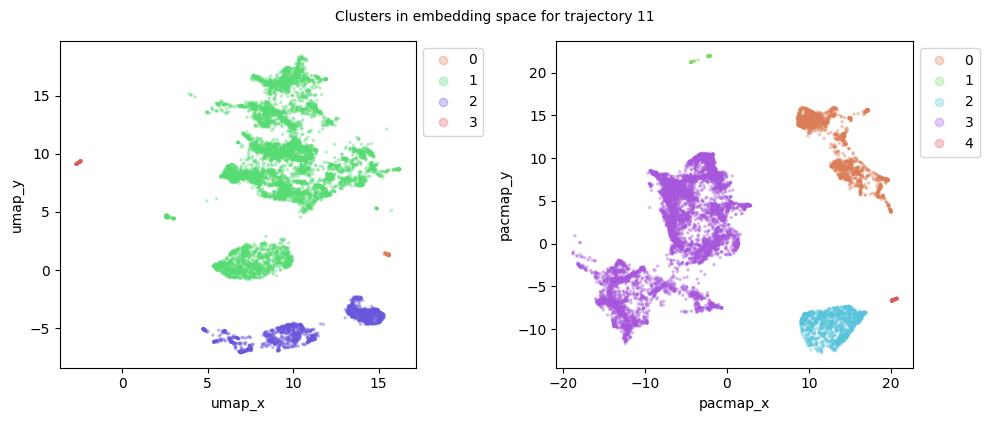

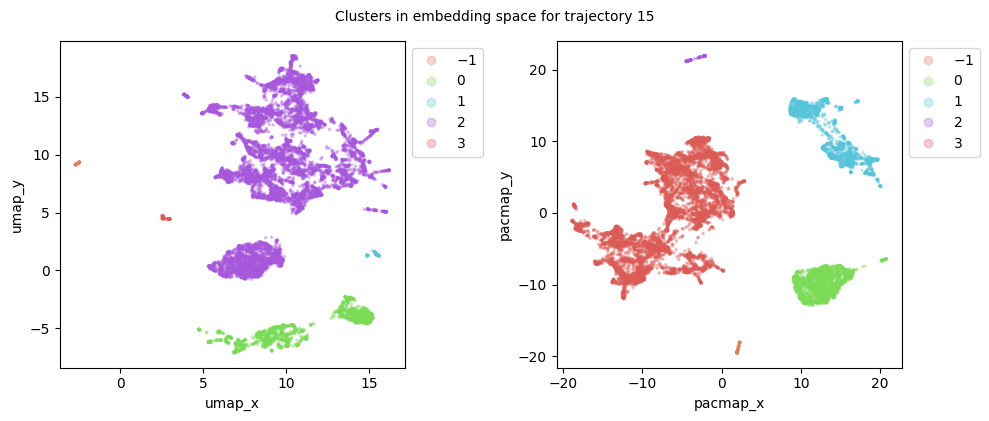

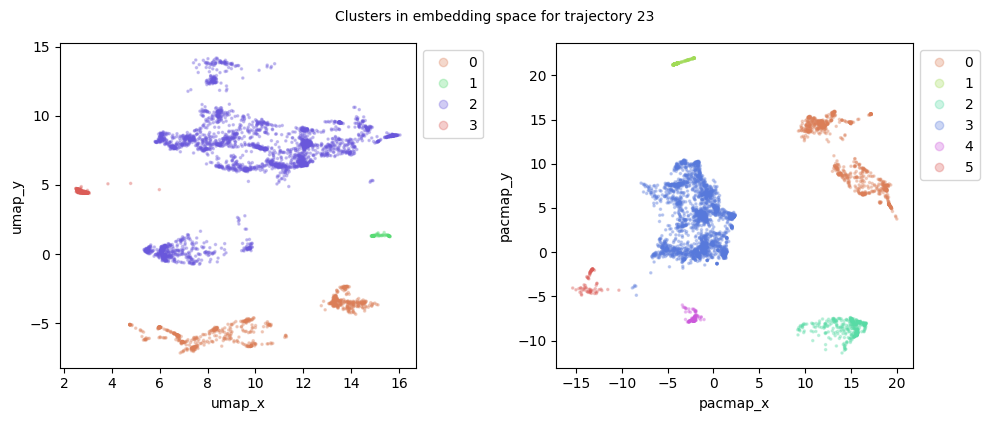

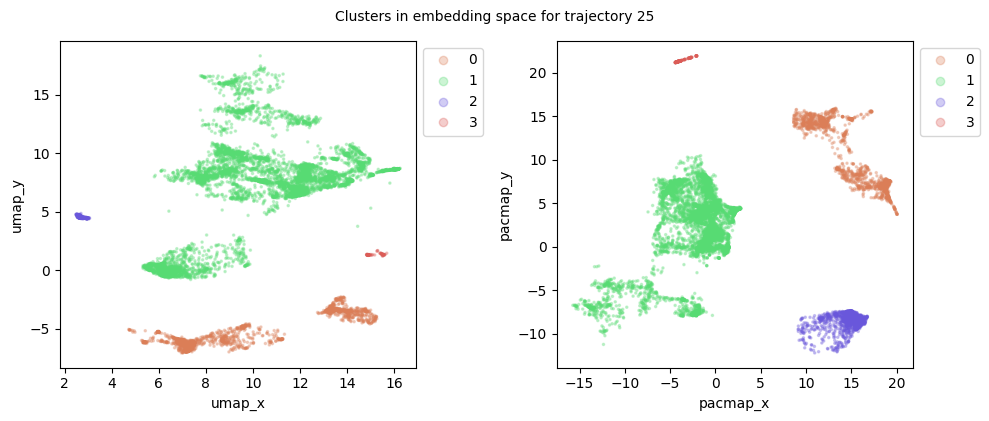

In [ ]:
Clusters.plotResults(nfigures=6)

In [ ]:
Clusters.getSimilarClusters(algorithm = 'umap', threshold = 5)
Clusters.unifyClusters(algorithm='umap')

Clusters.getSimilarClusters(algorithm = 'pacmap', threshold = 5)
Clusters.unifyClusters(algorithm='pacmap')

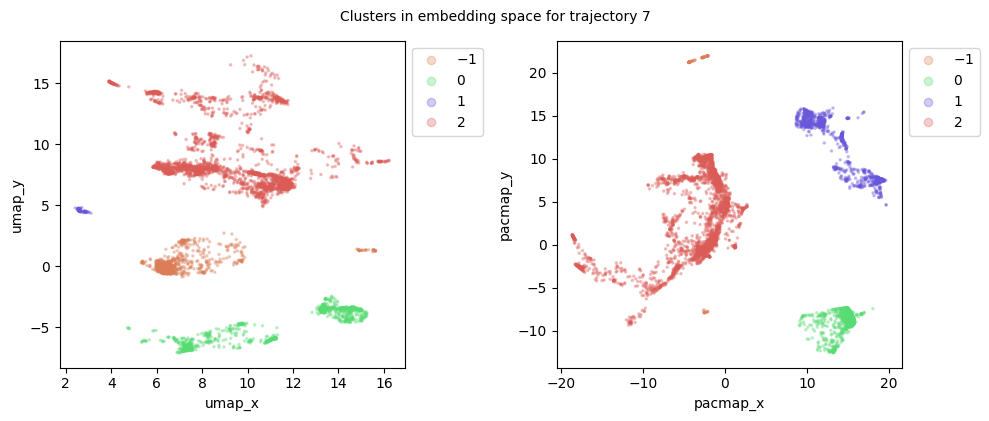

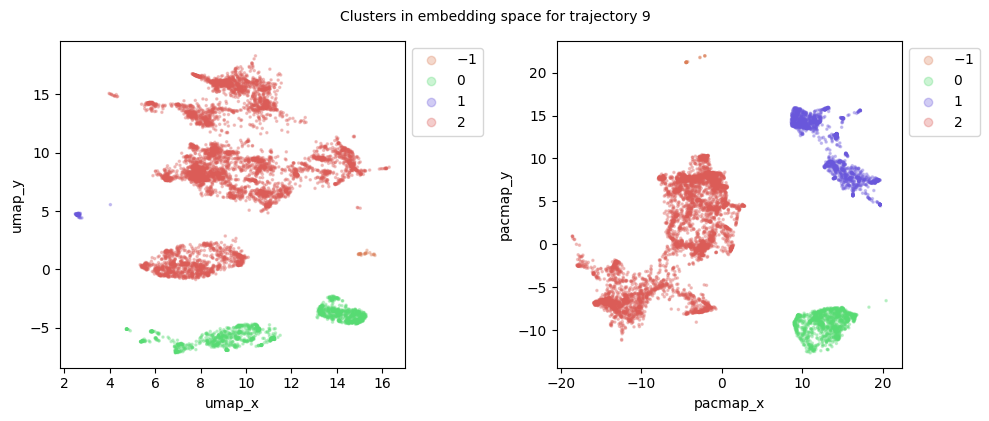

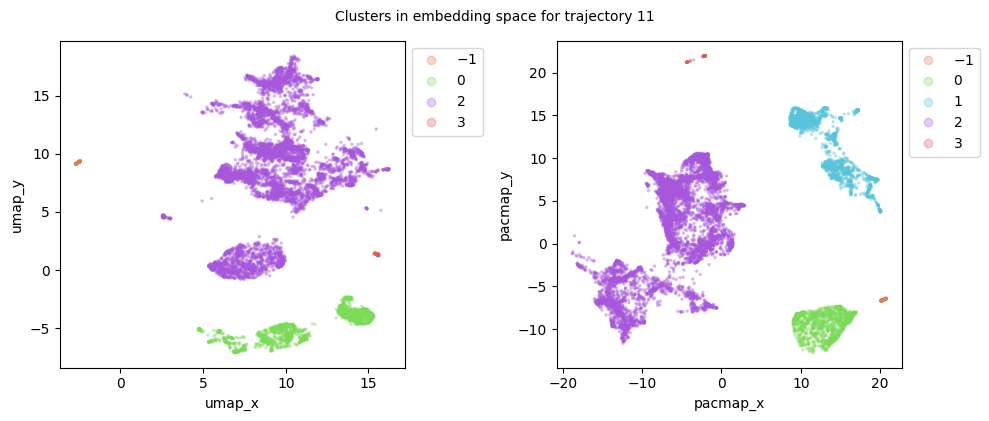

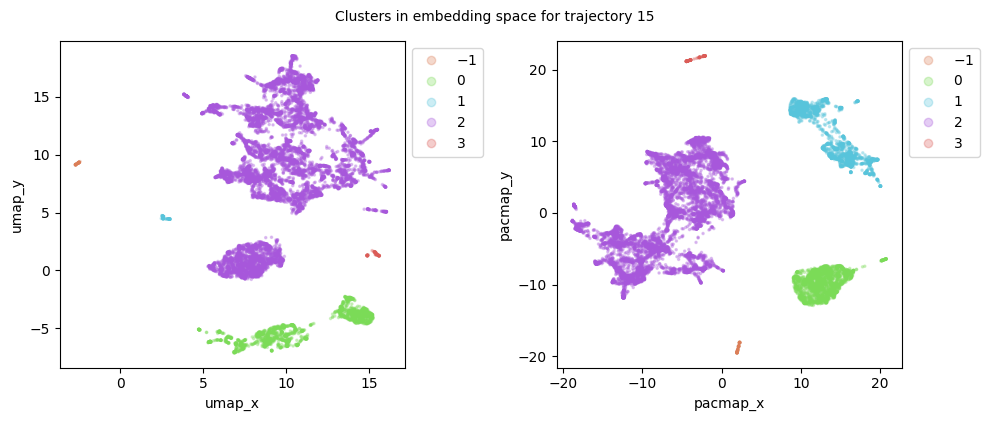

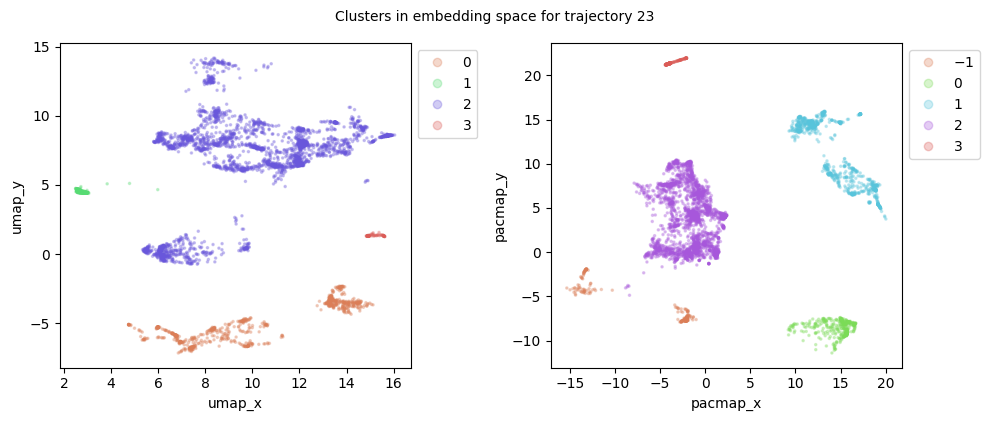

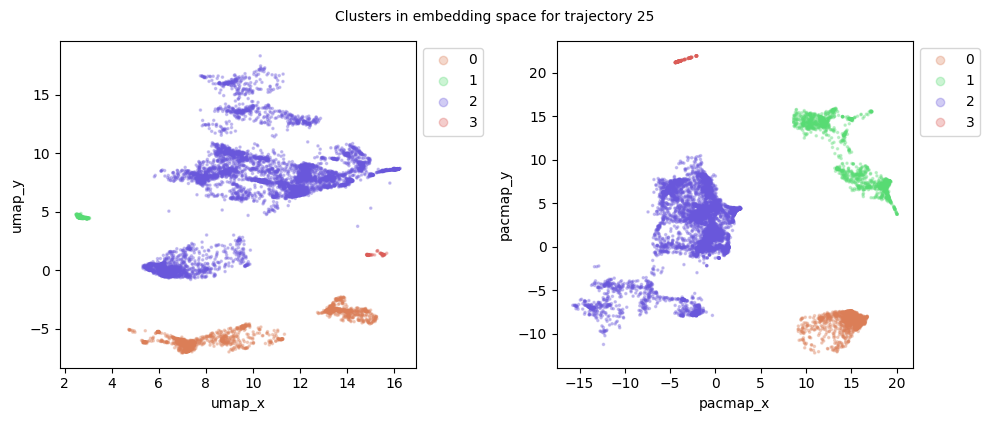

In [ ]:
Clusters.plotResults(nfigures=6, 
                     label_color='real_cluster')

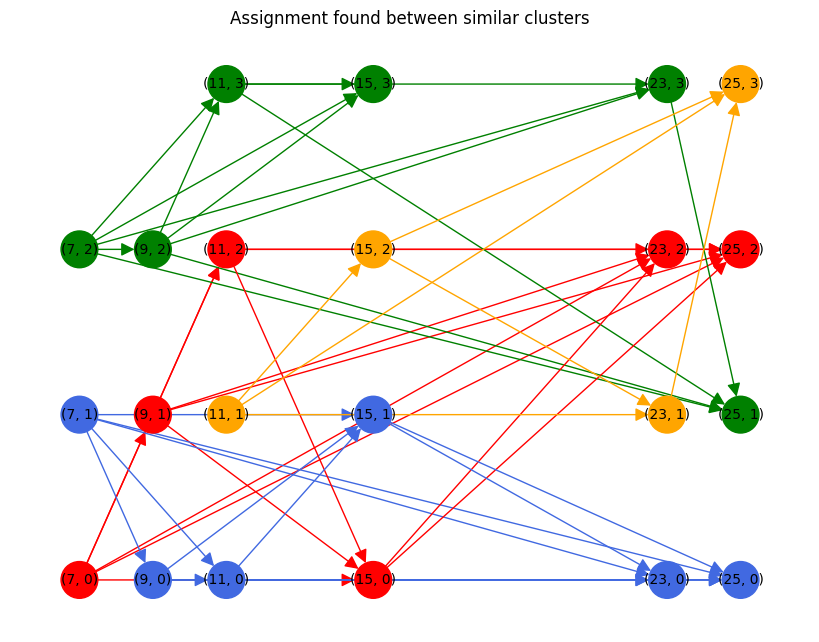

In [ ]:
Clusters.plotGraph()

In [ ]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 3, 
                    idxVariable     = 6, 
                    algorithm       = 'pacmap')